Experiment Plan

Experiement | Hypothesis | Expected benefit | Potential quality impact | Metrics | Success criteria

1. Smaller model for planning
- Planning may not need the strongest model
- lower planning cost + latency
- worse plan quality, more later step
- task success, plan success, steps, latency, cost
- quality drop <= 2 percentage points and cost/latency improves

2. Smaller model for routing
- Routing is simpler for classification task
- cheap routing
- wrong route/mode/tool
- routing accuracy, task success, cost
- routing accuracy stays high and total cost falls

3. Parallel tool execution
- Independent tools can run concurrently 
- lower wall-clock latency
- order/race issues if tools depend on each other
- latency, tool success, task success
- latency falls without quality regression

4. Context compression
- 30k input tokens likely contain redundant context
- fewer tokens, lower cost, lower latency
- important evidence may be dropped
- input tokens, groundness, task success, cost
- strong token reduction, quality drop <=2 points

5. RAG top-k reduction
- fewer chunks may be enough
- smaller context + lower cost
- Recall@K, groundness, success, tokens
- retrieval quality acceptable and cost/tokens improve

6.Prompt caching
- static/repeated prompt prefixes repeat work
- lower effective cost/latency
- stale/wrong cache key
- hit rate, success, cost, latency
- useful hit rate and unchanged quality

7. Early stopping
- 12 steps suggests possible over-reasoning
- fewer steps, lower latency/cost
- may stop before the task is complete
- steps, success, latency, cost
- steps fall while success remains near baseline

8. Model routing
- simple tasks can use cheaper models
- lower average cost
- wrong model for hard tasks
- success/model, cost/model, overall success
- cost moves toward target while quality remains near baselines

## Base line
- Average steps: 12
- Input tokens: 30,000
- Output tokens: 4,000
- Cost $0.18 / request

Target
- Latency < 8s
- Cost < $0.06 / request

Rule
- Không optimize cost/latency mà bỏ qua quality
- Mỗi experiment phải ghi:
   - Hypothesis
   - Expected benefit
   - Potential quality impact
   - Metrics
   - Success criteria

Và kết quả thực tế phải đo:
- Quality/task success
- Average steps
- Input tokens
- Output tokens
- Latency
- Cost

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)


## 1. Baseline and Target

In [3]:

BASELINE = {
    "name": "baseline",
    "quality": 0.92,  # replace with your measured value
    "avg_steps": 12.0,
    "input_tokens": 30_000,
    "output_tokens": 4_000,
    "latency_s": 18.0,
    "cost_usd": 0.18,
}

TARGET = {
    "latency_s": 8.0,
    "cost_usd": 0.06,
}

BASELINE


{'name': 'baseline',
 'quality': 0.92,
 'avg_steps': 12.0,
 'input_tokens': 30000,
 'output_tokens': 4000,
 'latency_s': 18.0,
 'cost_usd': 0.18}

## 2. Experiment plan

In [4]:

EXPERIMENT_CATALOG = pd.DataFrame([
    {
        "experiment": "smaller_model_planning",
        "hypothesis": "Planning tasks can use a smaller model without materially reducing plan quality.",
        "expected_benefit": "Lower planning latency and cost.",
        "potential_quality_impact": "Poorer plans may increase later steps or failures.",
        "metrics": "task_success, plan_success, avg_steps, latency_s, cost_usd",
        "success_criteria": "Task success drop <= 0.02 and cost or latency improves materially.",
    },
    {
        "experiment": "smaller_model_routing",
        "hypothesis": "Routing is simple enough for a smaller model.",
        "expected_benefit": "Lower routing cost and latency.",
        "potential_quality_impact": "Wrong route may send requests to the wrong model/tool.",
        "metrics": "routing_accuracy, task_success, latency_s, cost_usd",
        "success_criteria": "Routing accuracy stays near baseline and total cost falls.",
    },
    {
        "experiment": "parallel_tool_execution",
        "hypothesis": "Independent tool calls can run concurrently.",
        "expected_benefit": "Lower wall-clock latency.",
        "potential_quality_impact": "Dependent tools may break if parallelized.",
        "metrics": "task_success, tool_success, latency_s",
        "success_criteria": "Latency decreases and task/tool success stays stable.",
    },
    {
        "experiment": "context_compression",
        "hypothesis": "Much of the 30k-token context is unnecessary.",
        "expected_benefit": "Lower input tokens, cost, and possibly latency.",
        "potential_quality_impact": "Important context or evidence may be removed.",
        "metrics": "task_success, groundedness, input_tokens, latency_s, cost_usd",
        "success_criteria": "Input tokens fall substantially and quality drop <= 0.02.",
    },
    {
        "experiment": "rag_topk_reduction",
        "hypothesis": "Fewer retrieved chunks are sufficient for most tasks.",
        "expected_benefit": "Lower context size, tokens, and cost.",
        "potential_quality_impact": "Relevant evidence may be omitted.",
        "metrics": "Recall@K, task_success, groundedness, input_tokens, cost_usd",
        "success_criteria": "Cost/tokens improve while retrieval and task quality remain acceptable.",
    },
    {
        "experiment": "prompt_caching",
        "hypothesis": "Repeated prompt prefixes can be cached.",
        "expected_benefit": "Lower repeated-request latency and cost.",
        "potential_quality_impact": "Bad cache keys can return stale/mismatched data.",
        "metrics": "cache_hit_rate, task_success, latency_s, cost_usd",
        "success_criteria": "Meaningful hit rate with no quality regression.",
    },
    {
        "experiment": "early_stopping",
        "hypothesis": "The agent often continues after enough evidence is available.",
        "expected_benefit": "Lower steps, latency, and cost.",
        "potential_quality_impact": "Stopping too early may reduce correctness/completeness.",
        "metrics": "task_success, avg_steps, latency_s, cost_usd",
        "success_criteria": "Average steps decrease while task success drop <= 0.02.",
    },
    {
        "experiment": "model_routing",
        "hypothesis": "Simple tasks can use cheaper models while hard tasks use stronger models.",
        "expected_benefit": "Lower average cost with controlled quality.",
        "potential_quality_impact": "Router mistakes can hurt difficult tasks.",
        "metrics": "task_success, success_by_model, latency_s, cost_usd",
        "success_criteria": "Cost approaches target while task success remains near baseline.",
    },
])

EXPERIMENT_CATALOG


,experiment,hypothesis,expected_benefit,potential_quality_impact,metrics,success_criteria
0,smaller_model_planning,Planning tasks can use a smaller model without...,Lower planning latency and cost.,Poorer plans may increase later steps or failu...,"task_success, plan_success, avg_steps, latency...",Task success drop <= 0.02 and cost or latency ...
1,smaller_model_routing,Routing is simple enough for a smaller model.,Lower routing cost and latency.,Wrong route may send requests to the wrong mod...,"routing_accuracy, task_success, latency_s, cos...",Routing accuracy stays near baseline and total...
2,parallel_tool_execution,Independent tool calls can run concurrently.,Lower wall-clock latency.,Dependent tools may break if parallelized.,"task_success, tool_success, latency_s",Latency decreases and task/tool success stays ...
3,context_compression,Much of the 30k-token context is unnecessary.,"Lower input tokens, cost, and possibly latency.",Important context or evidence may be removed.,"task_success, groundedness, input_tokens, late...",Input tokens fall substantially and quality dr...
4,rag_topk_reduction,Fewer retrieved chunks are sufficient for most...,"Lower context size, tokens, and cost.",Relevant evidence may be omitted.,"Recall@K, task_success, groundedness, input_to...",Cost/tokens improve while retrieval and task q...
5,prompt_caching,Repeated prompt prefixes can be cached.,Lower repeated-request latency and cost.,Bad cache keys can return stale/mismatched data.,"cache_hit_rate, task_success, latency_s, cost_usd",Meaningful hit rate with no quality regression.
6,early_stopping,The agent often continues after enough evidenc...,"Lower steps, latency, and cost.",Stopping too early may reduce correctness/comp...,"task_success, avg_steps, latency_s, cost_usd",Average steps decrease while task success drop...
7,model_routing,Simple tasks can use cheaper models while hard...,Lower average cost with controlled quality.,Router mistakes can hurt difficult tasks.,"task_success, success_by_model, latency_s, cos...",Cost approaches target while task success rema...


## 3. Result schema

In [5]:

RESULT_COLUMNS = [
    "name",
    "quality",
    "avg_steps",
    "input_tokens",
    "output_tokens",
    "latency_s",
    "cost_usd",
]

results = pd.DataFrame([BASELINE], columns=RESULT_COLUMNS)
results


,name,quality,avg_steps,input_tokens,output_tokens,latency_s,cost_usd
0,baseline,0.92,12.0,30000,4000,18.0,0.18


In [6]:

demo_results = [
    {"name": "smaller_model_planning", "quality": 0.91, "avg_steps": 12.2, "input_tokens": 30000, "output_tokens": 4000, "latency_s": 15.5, "cost_usd": 0.145},
    {"name": "parallel_tool_execution", "quality": 0.92, "avg_steps": 12.0, "input_tokens": 30000, "output_tokens": 4000, "latency_s": 12.0, "cost_usd": 0.18},
    {"name": "context_compression", "quality": 0.91, "avg_steps": 11.5, "input_tokens": 16000, "output_tokens": 3800, "latency_s": 12.5, "cost_usd": 0.105},
    {"name": "rag_topk_reduction", "quality": 0.90, "avg_steps": 11.5, "input_tokens": 20000, "output_tokens": 3900, "latency_s": 13.5, "cost_usd": 0.125},
    {"name": "prompt_caching", "quality": 0.92, "avg_steps": 12.0, "input_tokens": 30000, "output_tokens": 4000, "latency_s": 13.0, "cost_usd": 0.13},
    {"name": "early_stopping", "quality": 0.90, "avg_steps": 7.5, "input_tokens": 22000, "output_tokens": 3000, "latency_s": 10.0, "cost_usd": 0.10},
    {"name": "model_routing", "quality": 0.91, "avg_steps": 10.0, "input_tokens": 22000, "output_tokens": 3200, "latency_s": 10.5, "cost_usd": 0.085},
]

results = pd.concat(
    [pd.DataFrame([BASELINE]), pd.DataFrame(demo_results)],
    ignore_index=True,
)

results


,name,quality,avg_steps,input_tokens,output_tokens,latency_s,cost_usd
0,baseline,0.92,12.0,30000,4000,18.0,0.180
1,smaller_model_planning,0.91,12.2,30000,4000,15.5,0.145
2,parallel_tool_execution,0.92,12.0,30000,4000,12.0,0.180
3,context_compression,0.91,11.5,16000,3800,12.5,0.105
4,rag_topk_reduction,0.90,11.5,20000,3900,13.5,0.125
5,prompt_caching,0.92,12.0,30000,4000,13.0,0.130
6,early_stopping,0.90,7.5,22000,3000,10.0,0.100
7,model_routing,0.91,10.0,22000,3200,10.5,0.085


## 4. So sánh với baseline

In [7]:

baseline = results.iloc[0]

comparison = results.copy()
comparison["quality_change"] = comparison["quality"] - baseline["quality"]
comparison["steps_change_pct"] = (comparison["avg_steps"] - baseline["avg_steps"]) / baseline["avg_steps"] * 100
comparison["input_tokens_change_pct"] = (comparison["input_tokens"] - baseline["input_tokens"]) / baseline["input_tokens"] * 100
comparison["latency_change_pct"] = (comparison["latency_s"] - baseline["latency_s"]) / baseline["latency_s"] * 100
comparison["cost_change_pct"] = (comparison["cost_usd"] - baseline["cost_usd"]) / baseline["cost_usd"] * 100

comparison[
    [
        "name",
        "quality",
        "quality_change",
        "avg_steps",
        "steps_change_pct",
        "input_tokens",
        "input_tokens_change_pct",
        "latency_s",
        "latency_change_pct",
        "cost_usd",
        "cost_change_pct",
    ]
]


,name,quality,quality_change,avg_steps,steps_change_pct,input_tokens,input_tokens_change_pct,latency_s,latency_change_pct,cost_usd,cost_change_pct
0,baseline,0.92,0.00,12.0,0.000000,30000,0.000000,18.0,0.000000,0.180,0.000000
1,smaller_model_planning,0.91,-0.01,12.2,1.666667,30000,0.000000,15.5,-13.888889,0.145,-19.444444
2,parallel_tool_execution,0.92,0.00,12.0,0.000000,30000,0.000000,12.0,-33.333333,0.180,0.000000
3,context_compression,0.91,-0.01,11.5,-4.166667,16000,-46.666667,12.5,-30.555556,0.105,-41.666667
4,rag_topk_reduction,0.90,-0.02,11.5,-4.166667,20000,-33.333333,13.5,-25.000000,0.125,-30.555556
5,prompt_caching,0.92,0.00,12.0,0.000000,30000,0.000000,13.0,-27.777778,0.130,-27.777778
6,early_stopping,0.90,-0.02,7.5,-37.500000,22000,-26.666667,10.0,-44.444444,0.100,-44.444444
7,model_routing,0.91,-0.01,10.0,-16.666667,22000,-26.666667,10.5,-41.666667,0.085,-52.777778


## 5. Success criteria

In [8]:

MAX_QUALITY_DROP = 0.02

def evaluate_candidate(row: pd.Series) -> pd.Series:
    quality_ok = row["quality"] >= BASELINE["quality"] - MAX_QUALITY_DROP
    latency_target_met = row["latency_s"] < TARGET["latency_s"]
    cost_target_met = row["cost_usd"] < TARGET["cost_usd"]

    return pd.Series({
        "quality_ok": quality_ok,
        "latency_target_met": latency_target_met,
        "cost_target_met": cost_target_met,
        "meets_all_targets": quality_ok and latency_target_met and cost_target_met,
    })

criteria = results.apply(evaluate_candidate, axis=1)
scored_results = pd.concat([results, criteria], axis=1)
scored_results


,name,quality,avg_steps,input_tokens,output_tokens,latency_s,cost_usd,quality_ok,latency_target_met,cost_target_met,meets_all_targets
0,baseline,0.92,12.0,30000,4000,18.0,0.180,True,False,False,False
1,smaller_model_planning,0.91,12.2,30000,4000,15.5,0.145,True,False,False,False
2,parallel_tool_execution,0.92,12.0,30000,4000,12.0,0.180,True,False,False,False
3,context_compression,0.91,11.5,16000,3800,12.5,0.105,True,False,False,False
4,rag_topk_reduction,0.90,11.5,20000,3900,13.5,0.125,True,False,False,False
5,prompt_caching,0.92,12.0,30000,4000,13.0,0.130,True,False,False,False
6,early_stopping,0.90,7.5,22000,3000,10.0,0.100,True,False,False,False
7,model_routing,0.91,10.0,22000,3200,10.5,0.085,True,False,False,False


Một experiment riêng lẻ không nhất thiết phải đạt cả 2 target cuối cùng.

Ví dụ:
- Parallel tools chủ yếu giảm latency
- Context compression chủ yêu giảm tokens/cost
- Routing chủ yếu giảm cost
- Early stopping giảm steps + latency + cost

Chỉ combine experiment đã chứng minh không gây quality regression đáng kể

## 6. Visualize trade-offs

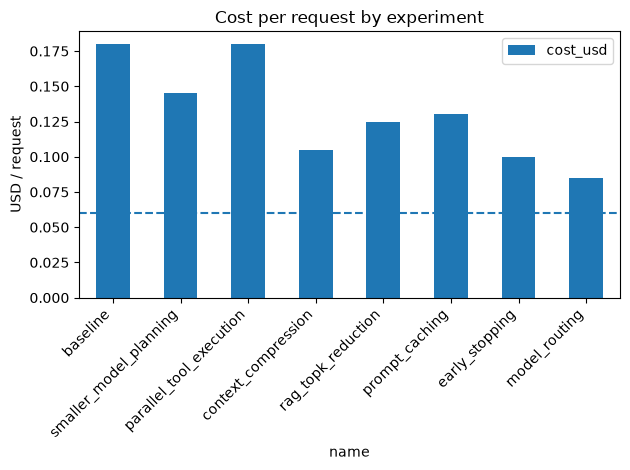

In [9]:

ax = results.plot(kind="bar", x="name", y="cost_usd", title="Cost per request by experiment")
ax.axhline(TARGET["cost_usd"], linestyle="--")
ax.set_ylabel("USD / request")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


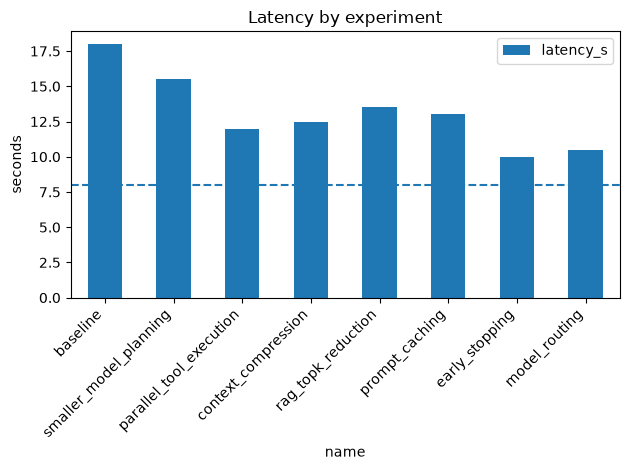

In [10]:

ax = results.plot(kind="bar", x="name", y="latency_s", title="Latency by experiment")
ax.axhline(TARGET["latency_s"], linestyle="--")
ax.set_ylabel("seconds")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


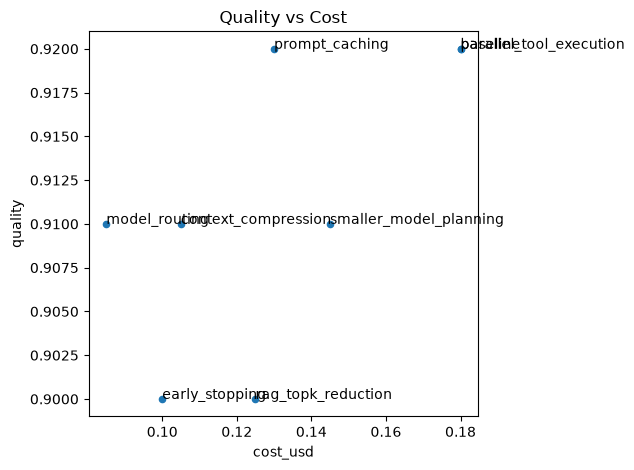

In [11]:

ax = results.plot(kind="scatter", x="cost_usd", y="quality", title="Quality vs Cost")
for _, row in results.iterrows():
    ax.annotate(row["name"], (row["cost_usd"], row["quality"]))
plt.tight_layout()
plt.show()


## 7. Recommended experiment order

### Phase A - Low-risk/easy to isolate

1. Smaller model for routing
2. Prompt caching
3. Parallel tool execution

### Phase B - Token reduction
4. Context compression
5. RAG top-k reduction

Baseline input = 30k tokens. nen day la cung co tiem nang tiet kem lon nhat

### Phase C - Control flow
6. Early stopping
7. Smaller model for planning

Baseline = 12 steps, nen kiem tra Agent co over-reasoning khong

### Phase D - Combined routing
8. Model routing

Chi lam sau khi da hieu task nao an toan voi model nho

